# Cat vs Dog Classifier
Using `ImageDataGenerator` — изображения подаются батчами, не грузятся все в память.

In [1]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

I0000 00:00:1775140797.887743   29002 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1775140797.929051   29002 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1775140798.836508   29002 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


## 1. Проверка датасета

In [2]:
data = Path("./PetImages")

cat_images = list(data.glob("Cat/*.jpg"))
dog_images = list(data.glob("Dog/*.jpg"))

print(f"Кошек: {len(cat_images)}")
print(f"Собак: {len(dog_images)}")
print(f"Всего: {len(cat_images) + len(dog_images)}")

Кошек: 12499
Собак: 12499
Всего: 24998


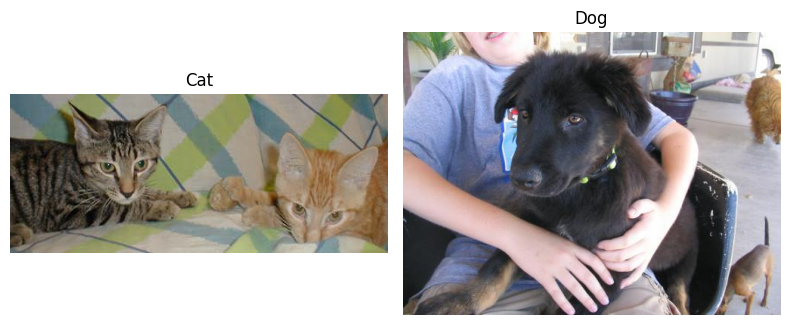

In [3]:
# Показать пример кошки и собаки
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Ищем первый читаемый файл
for path in cat_images:
    try:
        img = Image.open(str(path))
        axes[0].imshow(img)
        axes[0].set_title("Cat")
        axes[0].axis("off")
        break
    except Exception:
        continue

for path in dog_images:
    try:
        img = Image.open(str(path))
        axes[1].imshow(img)
        axes[1].set_title("Dog")
        axes[1].axis("off")
        break
    except Exception:
        continue

plt.tight_layout()
plt.show()

## 2. Очистка повреждённых файлов

В датасете PetImages есть несколько повреждённых JPG — их нужно удалить перед обучением.

In [4]:
import os

removed = 0
for folder in ["Cat", "Dog"]:
    for fpath in (data / folder).glob("*.jpg"):
        try:
            img = Image.open(fpath)
            img.verify()  # проверяет без полного декодирования
        except Exception:
            os.remove(fpath)
            removed += 1

print(f"Удалено повреждённых файлов: {removed}")

/home/meyigi/personal/personal/tech-playground/artificial_intelligence/.venv/lib/python3.13/site-packages/PIL/TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Удалено повреждённых файлов: 0


## 3. Подготовка данных через ImageDataGenerator

Вместо загрузки всех 28k+ изображений в память — используем генератор, который читает батчами с диска.

In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (150, 150)  # размер входного изображения
BATCH_SIZE = 32

# Аугментация только для обучения
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
)

# Для валидации — только нормализация
val_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.2,
)

train_gen = train_datagen.flow_from_directory(
    "./PetImages",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    seed=42,
)

val_gen = val_datagen.flow_from_directory(
    "./PetImages",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    seed=42,
)

print("Классы:", train_gen.class_indices)

Found 20000 images belonging to 2 classes.
Found 4998 images belonging to 2 classes.
Классы: {'Cat': 0, 'Dog': 1}


## 4. Модель (CNN)

In [6]:
model = tf.keras.Sequential([
    # Блок 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", input_shape=(*IMG_SIZE, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Блок 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Блок 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Классификатор
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid"),  # 0 = Cat, 1 = Dog
])

model.summary()

/home/meyigi/personal/personal/tech-playground/artificial_intelligence/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1775140805.165513   29002 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1775140805.166020   29088 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1775140805.187969   29002 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,470,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,563,713 (36.48 MB)

 Trainable params: 9,563,713 (36.48 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

## 5. Обучение

In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_model.keras", save_best_only=True),
]

history = model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    callbacks=callbacks,
)

Epoch 1/10


I0000 00:00:1775140805.518851   29002 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
W0000 00:00:1775140806.010009   29002 cpu_allocator_impl.cc:82] Allocation of 37879808 exceeds 10% of free system memory.
W0000 00:00:1775140806.511104   29111 cpu_allocator_impl.cc:82] Allocation of 89718784 exceeds 10% of free system memory.


625/625 ━━━━━━━━━━━━━━━━━━━━ 310s 494ms/step - accuracy: 0.6346 - loss: 0.6378 - val_accuracy: 0.6737 - val_loss: 0.6108
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 336s 537ms/step - accuracy: 0.7297 - loss: 0.5396 - val_accuracy: 0.7925 - val_loss: 0.4455
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 336s 538ms/step - accuracy: 0.7655 - loss: 0.4870 - val_accuracy: 0.8125 - val_loss: 0.4142
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 338s 541ms/step - accuracy: 0.7909 - loss: 0.4497 - val_accuracy: 0.8191 - val_loss: 0.4122
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 340s 543ms/step - accuracy: 0.8076 - loss: 0.4234 - val_accuracy: 0.8409 - val_loss: 0.3631
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 332s 530ms/step - accuracy: 0.8221 - loss: 0.3976 - val_accuracy: 0.8495 - val_loss: 0.3429
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 336s 537ms/step - accuracy: 0.8357 - loss: 0.3758 - val_accuracy: 0.8515 - val_loss: 0.3453
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 333s 533ms/step - accuracy: 0.8454 - loss: 0.35

## 6. Графики обучения

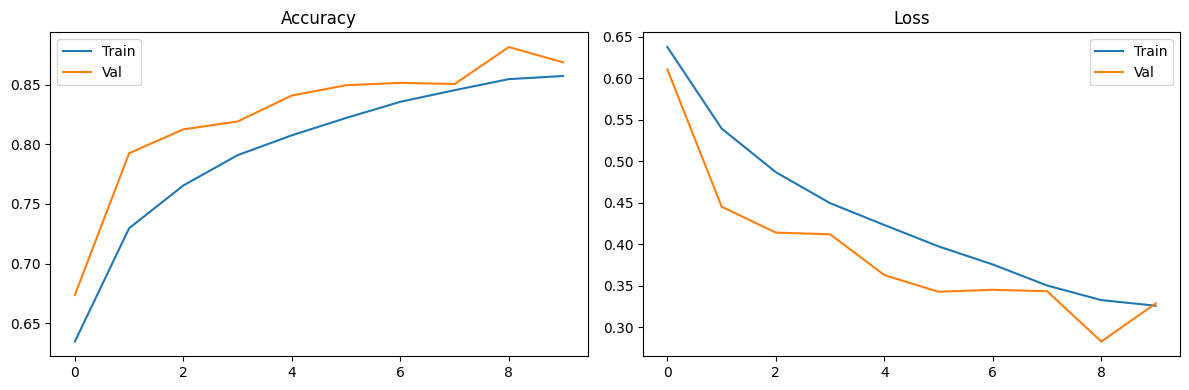

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Val")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Val")
axes[1].set_title("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Предсказание на одном изображении

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


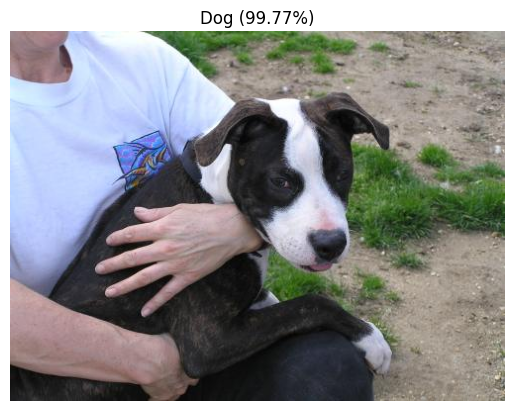

In [16]:
def predict_image(img_path):
    img = Image.open(img_path).resize(IMG_SIZE)
    arr = np.array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)  # (1, 150, 150, 3)
    prob = model.predict(arr)[0][0]
    label = "Dog" if prob > 0.5 else "Cat"
    plt.imshow(Image.open(img_path))
    plt.title(f"{label} ({prob:.2%})")
    plt.axis("off")
    plt.show()

# Пример — замени путь на свой
predict_image(str(dog_images[1]))